# 📊 01 — Exploratory Data Analysis
### FraudShield | IEEE-CIS Fraud Detection | Phase 1 of the project tracker

**Goal:** understand class imbalance, time structure, missingness, and fraud signals *before* any modeling.

**What this notebook answers (maps to tracker tasks 1.1 – 1.10):**

| Tracker | Section | Question |
|---|---|---|
| 1.1 | 1 | What does the raw data look like? (shape, dtypes, nulls, duplicates) |
| 1.2 | 2 | How much of the data has identity info, and does it matter? |
| 1.3 | 3 | How imbalanced is fraud? |
| 1.4 | 4 | How does fraud change over time, and where should the train / validation / holdout cut go? |
| 1.5 | 5 | Do fraudulent amounts look different? |
| 1.6 | 6 | Which product / card / device groups are riskier? |
| 1.7 | 7 | Do email domains carry signal? |
| 1.8 | 8 | Is *missingness itself* a signal? |
| 1.9 | 9 | Can we reconstruct a card identity (needed for velocity features in Phase 2)? |
| 1.10 | 11 | Key findings in plain business language |

**Before running:**
1. Accept the competition rules on Kaggle and download `train_transaction.csv` and `train_identity.csv` into `data/raw/`.
2. Expected location relative to this notebook: `../../data/raw/` (override with the `FRAUD_DATA_DIR` environment variable).
3. Needs roughly **4–6 GB of RAM** while loading (columns are downcast right after reading).
4. Install: `pandas numpy matplotlib` (nothing else required).

> ⚠️ **EDA ≠ feature engineering.** Several cells below look at the *whole* dataset (for example group sizes), which uses future information. That is fine for understanding the data, but anything built in Phase 2 must use **past data only**.

## 0. Setup & configuration

In [2]:
import gc
import json
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

# ---- Configuration -------------------------------------------------------
DATA_DIR      = Path(os.environ.get("FRAUD_DATA_DIR", "../../data/raw"))
ARTIFACTS_DIR = Path(os.environ.get("FRAUD_ARTIFACTS_DIR", "../artifacts"))
FIG_DIR       = Path(os.environ.get("FRAUD_FIG_DIR", "../../docs/eda_figures"))
SAVE_FIGS     = True          # save every figure as a PNG for the README / docs
COLORS        = {"legit": "#3B82F6", "fraud": "#EF4444", "neutral": "#94A3B8"}


def save_fig(name):
    # Save the current figure to FIG_DIR (call right before plt.show()).
    if SAVE_FIGS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


print("Data dir     :", DATA_DIR.resolve())
print("Artifacts dir:", ARTIFACTS_DIR.resolve())
print("Figures dir  :", FIG_DIR.resolve())

Data dir     : C:\VS CODE\PROJECTS\FraudShield AI\data\raw
Artifacts dir: C:\VS CODE\PROJECTS\FraudShield AI\ml\artifacts
Figures dir  : C:\VS CODE\PROJECTS\FraudShield AI\docs\eda_figures


## 1. Load data & first look  *(tracker 1.1)*

We downcast numeric columns and turn text columns into categoricals right after reading. This cuts memory by more than half, which matters on a laptop.

In [3]:
def reduce_mem(df):
    # Downcast numerics and convert text columns to category to save memory.
    for c in df.columns:
        t = df[c].dtype
        if isinstance(t, pd.CategoricalDtype):
            continue
        if t == "float64":
            df[c] = df[c].astype("float32")
        elif t == "int64":
            df[c] = pd.to_numeric(df[c], downcast="integer")
        elif t == "object" or pd.api.types.is_string_dtype(t):
            df[c] = df[c].astype("category")
    return df


txn   = reduce_mem(pd.read_csv(DATA_DIR / "train_transaction.csv"))
ident = reduce_mem(pd.read_csv(DATA_DIR / "train_identity.csv"))

print(f"Transactions : {txn.shape[0]:>9,} rows x {txn.shape[1]} columns")
print(f"Identity     : {ident.shape[0]:>9,} rows x {ident.shape[1]} columns")
print(f"Memory (txn) : {txn.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

Transactions :   590,540 rows x 394 columns
Identity     :   144,233 rows x 41 columns
Memory (txn) : 903 MB


In [4]:
# Column dtypes at a glance
display(txn.dtypes.astype(str).value_counts().rename("n_columns").to_frame())

# Duplicates
print("Duplicate TransactionIDs (transaction table):", txn["TransactionID"].duplicated().sum())
print("Duplicate TransactionIDs (identity table)   :", ident["TransactionID"].duplicated().sum())
print("Fully duplicated rows (ignoring ID)         :", txn.drop(columns="TransactionID").duplicated().sum())

,n_columns
float32,376
category,14
int32,2
int8,1
int16,1


Duplicate TransactionIDs (transaction table): 0
Duplicate TransactionIDs (identity table)   : 0
Fully duplicated rows (ignoring ID)         : 3


In [5]:
# Null summary
null_pct = txn.isna().mean().sort_values(ascending=False) * 100
print(f"Columns with  >90% nulls : {(null_pct > 90).sum()}")
print(f"Columns with  >50% nulls : {(null_pct > 50).sum()}")
print(f"Columns with   0% nulls  : {(null_pct == 0).sum()}  (of {len(null_pct)})")
display(null_pct.head(15).round(1).to_frame("null_%"))

Columns with  >90% nulls : 2
Columns with  >50% nulls : 174
Columns with   0% nulls  : 20  (of 394)


,null_%
dist2,93.6000
D7,93.4000
D13,89.5000
D14,89.5000
D12,89.0000
D6,87.6000
D9,87.3000
D8,87.3000
V153,86.1000
V149,86.1000


In [6]:
# The human-readable columns we plan to use in the UI and in explanations
READABLE = [
    "TransactionAmt", "ProductCD", "card4", "card6", "addr1", "addr2",
    "P_emaildomain", "R_emaildomain", "DeviceType", "DeviceInfo",
]
all_cols = set(txn.columns) | set(ident.columns)
readable_report = pd.DataFrame({
    "present": [c in all_cols for c in READABLE],
    "null_%": [
        (txn[c].isna().mean() * 100) if c in txn.columns
        else (ident[c].isna().mean() * 100) if c in ident.columns else np.nan
        for c in READABLE
    ],
}, index=READABLE)
display(readable_report.round(1))

,present,null_%
TransactionAmt,True,0.0000
ProductCD,True,0.0000
card4,True,0.3000
card6,True,0.3000
addr1,True,11.1000
addr2,True,11.1000
P_emaildomain,True,16.0000
R_emaildomain,True,76.8000
DeviceType,True,2.4000
DeviceInfo,True,17.7000


> **Note:** `DeviceType` and `DeviceInfo` live in the **identity** table, which only covers part of the transactions. Their null rate above is therefore measured on identity rows only; it is much higher after the merge below.

## 2. Merge transaction + identity  *(tracker 1.2)*

Identity data is only available for a subset of transactions. We left-join so that **every transaction is kept**, and add a `has_identity` flag so we can check whether having identity data is itself informative.

In [7]:
has_identity = txn["TransactionID"].isin(ident["TransactionID"])

df = txn.merge(ident, on="TransactionID", how="left", validate="one_to_one")
df["has_identity"] = has_identity.values

del txn, ident, has_identity
gc.collect()

y = df["isFraud"]
print(f"Merged shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

cov = df.groupby("has_identity")["isFraud"].agg(transactions="count", fraud_rate="mean")
cov["share_of_transactions_%"] = cov["transactions"] / len(df) * 100
display(cov)

Merged shape: 590,540 rows x 435 columns


C:\Users\aksha\AppData\Local\Temp\ipykernel_5908\3019456386.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["has_identity"] = has_identity.values


,transactions,fraud_rate,share_of_transactions_%
has_identity,,,
False,446307,0.0209,75.5761
True,144233,0.0785,24.4239


**How to read this:** if `fraud_rate` differs a lot between rows with and without identity data, then *"do we have identity info?"* is a feature by itself, and the serving API must handle the "no identity" case gracefully (the manual form in the demo will often have none).

## 3. Class balance  *(tracker 1.3)*

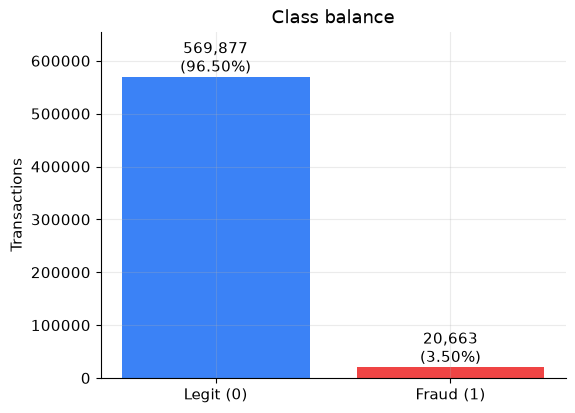

Fraud rate: 3.50%  (about 1 in 29 transactions)
A model that approves EVERYTHING scores 96.50% accuracy -> accuracy is useless here.
Use PR-AUC and recall at a fixed false-positive rate instead.


In [8]:
fraud_rate = y.mean()
counts = y.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(["Legit (0)", "Fraud (1)"], counts.values, color=[COLORS["legit"], COLORS["fraud"]])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(df):.2%})", ha="center", va="bottom")
ax.set_title("Class balance")
ax.set_ylabel("Transactions")
ax.set_ylim(0, counts.max() * 1.15)
save_fig("01_class_balance")
plt.show()

print(f"Fraud rate: {fraud_rate:.2%}  (about 1 in {int(round(1 / fraud_rate))} transactions)")
print(f"A model that approves EVERYTHING scores {1 - fraud_rate:.2%} accuracy -> accuracy is useless here.")
print("Use PR-AUC and recall at a fixed false-positive rate instead.")

## 4. Fraud over time & the train / validation / holdout split  *(tracker 1.4)*

`TransactionDT` is a **time offset in seconds** from an unspecified reference moment (not a real timestamp). It is still perfect for ordering transactions, which is all a time-based split needs.

Why this matters: random splits let the model "peek" at the future. Training on the past and testing on the future matches how the system would run in production.

C:\Users\aksha\AppData\Local\Temp\ipykernel_5908\3542287244.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["day"] = (df["TransactionDT"] // 86400).astype("int32")


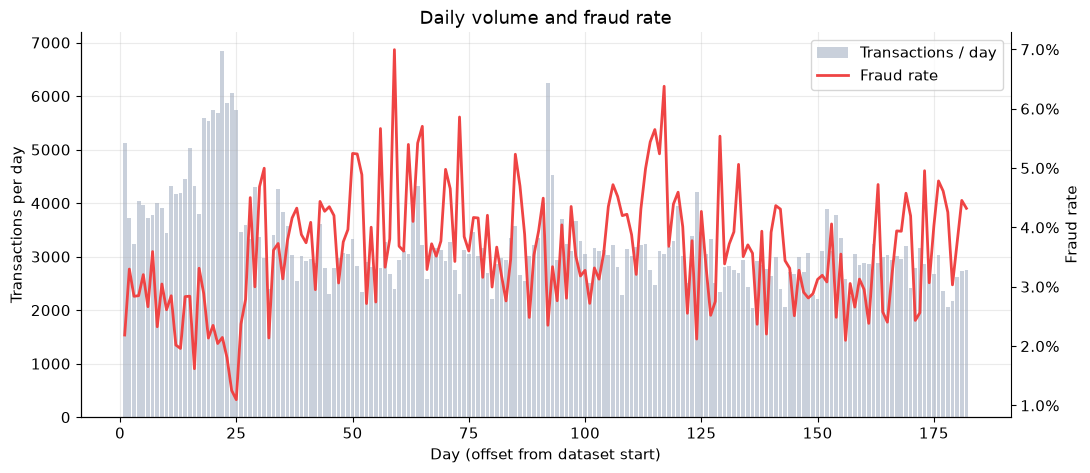

Dataset spans 1 to 182 days (182 days).
Daily fraud rate: min 1.10% | median 3.56% | max 6.99%


In [9]:
df["day"] = (df["TransactionDT"] // 86400).astype("int32")

daily = df.groupby("day")["isFraud"].agg(transactions="count", fraud_rate="mean")

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(daily.index, daily["transactions"], color=COLORS["neutral"], alpha=0.5, label="Transactions / day")
ax1.set_xlabel("Day (offset from dataset start)")
ax1.set_ylabel("Transactions per day")

ax2 = ax1.twinx()
ax2.plot(daily.index, daily["fraud_rate"], color=COLORS["fraud"], lw=2, label="Fraud rate")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.set_ylabel("Fraud rate")
ax2.grid(False)
ax2.spines["right"].set_visible(True)

ax1.set_title("Daily volume and fraud rate")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
save_fig("02_daily_volume_fraud_rate")
plt.show()

print(f"Dataset spans {daily.index.min()} to {daily.index.max()} days "
      f"({daily.index.max() - daily.index.min() + 1} days).")
print(f"Daily fraud rate: min {daily['fraud_rate'].min():.2%} | "
      f"median {daily['fraud_rate'].median():.2%} | max {daily['fraud_rate'].max():.2%}")

In [10]:
# Proposed time-based split: first 70% of time -> train, next 15% -> validation, last 15% -> holdout
q = df["TransactionDT"].quantile([0.70, 0.85])
train_end_dt, val_end_dt = int(q.loc[0.70]), int(q.loc[0.85])
max_dt = int(df["TransactionDT"].max())

split = pd.cut(
    df["TransactionDT"],
    bins=[-1, train_end_dt, val_end_dt, max_dt],
    labels=["train", "validation", "holdout"],
)

split_summary = df.groupby(split, observed=True).agg(
    rows=("isFraud", "count"),
    fraud_rate=("isFraud", "mean"),
    start_day=("day", "min"),
    end_day=("day", "max"),
)
display(split_summary)
print("Rule: the holdout set stays untouched until final evaluation and the live simulator.")
print("Check: fraud rate should be roughly similar across the three sets (big gaps = drift to discuss).")

del split

,rows,fraud_rate,start_day,end_day
TransactionDT,,,,
train,413378,0.0352,1,120
validation,88581,0.0343,120,152
holdout,88581,0.0348,152,182


Rule: the holdout set stays untouched until final evaluation and the live simulator.
Check: fraud rate should be roughly similar across the three sets (big gaps = drift to discuss).


C:\Users\aksha\AppData\Local\Temp\ipykernel_5908\2351732611.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["hour_rel"] = ((df["TransactionDT"] // 3600) % 24).astype("int8")
C:\Users\aksha\AppData\Local\Temp\ipykernel_5908\2351732611.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["dow_rel"]  = (df["day"] % 7).astype("int8")


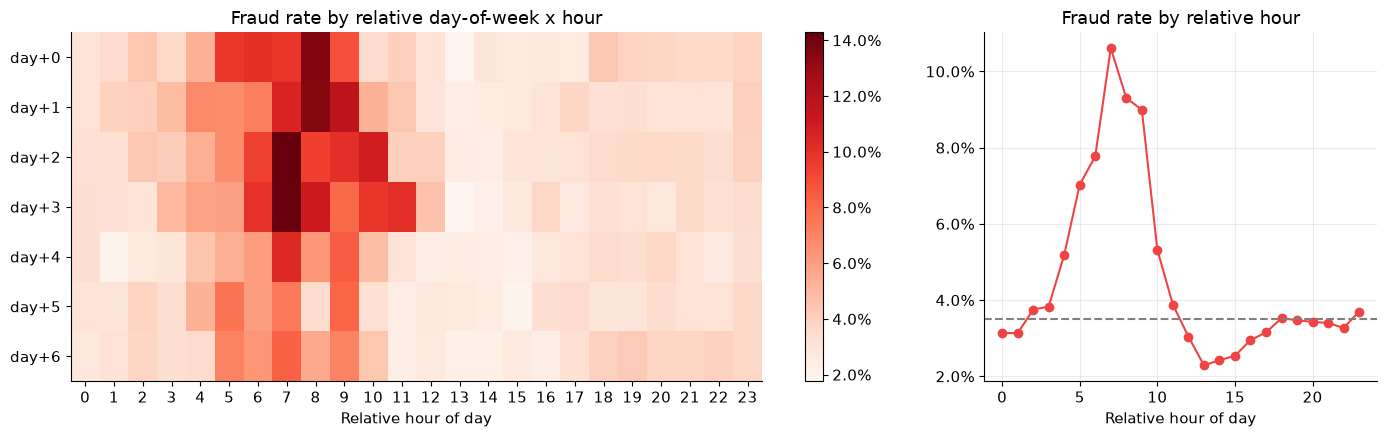

In [11]:
# 💡 Optional: hour-of-day / day-of-week patterns.
# TransactionDT has no known reference date, so these are RELATIVE hours and weekdays
# (offset 0 is arbitrary). The pattern can still be informative, but do not label hour 3 as "3 AM".
df["hour_rel"] = ((df["TransactionDT"] // 3600) % 24).astype("int8")
df["dow_rel"]  = (df["day"] % 7).astype("int8")

pivot = df.pivot_table(index="dow_rel", columns="hour_rel", values="isFraud", aggfunc="mean", observed=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
im = axes[0].imshow(pivot.values, aspect="auto", cmap="Reds")
axes[0].set_xticks(range(24))
axes[0].set_xticklabels(pivot.columns)
axes[0].set_yticks(range(len(pivot.index)))
axes[0].set_yticklabels([f"day+{d}" for d in pivot.index])
axes[0].set_xlabel("Relative hour of day")
axes[0].set_title("Fraud rate by relative day-of-week x hour")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], format=PercentFormatter(1.0))

hourly = df.groupby("hour_rel")["isFraud"].mean()
axes[1].plot(hourly.index, hourly.values, marker="o", color=COLORS["fraud"])
axes[1].axhline(fraud_rate, ls="--", color="gray")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_xlabel("Relative hour of day")
axes[1].set_title("Fraud rate by relative hour")
plt.tight_layout()
save_fig("03_hour_dow_heatmap")
plt.show()

## 5. Transaction amount  *(tracker 1.5)*

,count,mean,std,min,50%,90%,99%,max
isFraud,,,,,,,,
0,"569,877.0000",134.5117,239.3951,0.2510,68.5000,267.1120,"1,104.0000","31,937.3906"
1,"20,663.0000",149.2448,232.2122,0.2920,75.0000,335.0000,994.0000,"5,191.0000"


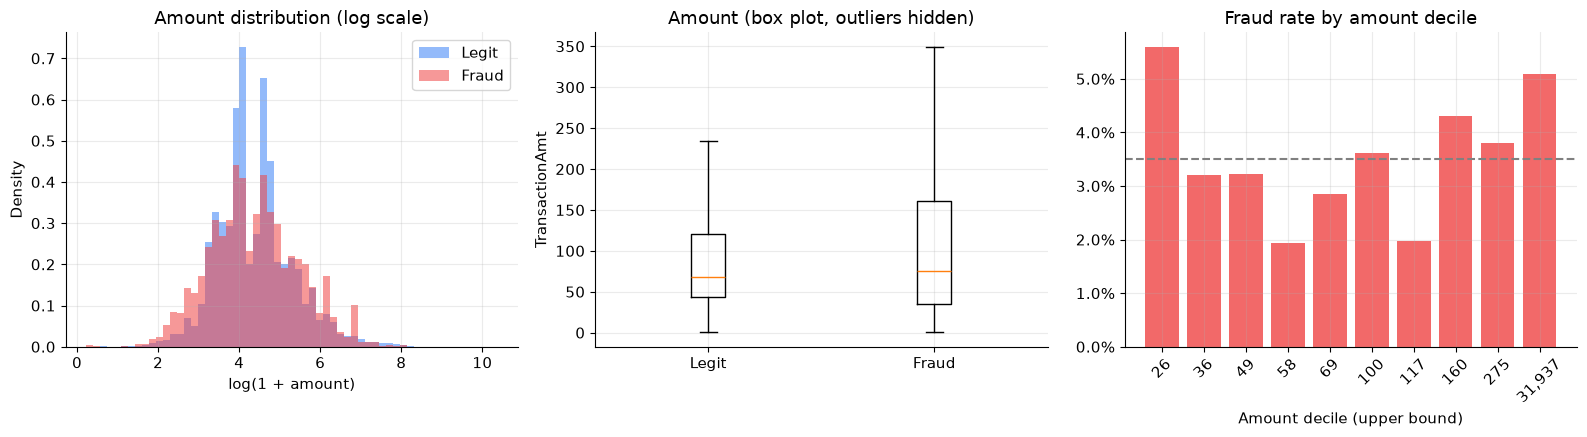

In [12]:
display(df.groupby("isFraud")["TransactionAmt"].describe(percentiles=[0.5, 0.9, 0.99]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) distribution on a log scale
log_amt = np.log1p(df["TransactionAmt"])
bins = np.linspace(log_amt.min(), log_amt.max(), 60)
axes[0].hist(log_amt[y == 0], bins=bins, density=True, alpha=0.55, color=COLORS["legit"], label="Legit")
axes[0].hist(log_amt[y == 1], bins=bins, density=True, alpha=0.55, color=COLORS["fraud"], label="Fraud")
axes[0].set_xlabel("log(1 + amount)")
axes[0].set_ylabel("Density")
axes[0].set_title("Amount distribution (log scale)")
axes[0].legend()

# (b) box plot
axes[1].boxplot(
    [df.loc[y == 0, "TransactionAmt"].clip(upper=1500), df.loc[y == 1, "TransactionAmt"].clip(upper=1500)],
    showfliers=False,
)
axes[1].set_xticklabels(["Legit", "Fraud"])
axes[1].set_title("Amount (box plot, outliers hidden)")
axes[1].set_ylabel("TransactionAmt")

# (c) fraud rate by amount decile
amt_bin = pd.qcut(df["TransactionAmt"], 10, duplicates="drop")
rate = df.groupby(amt_bin, observed=True)["isFraud"].mean()
axes[2].bar(range(len(rate)), rate.values, color=COLORS["fraud"], alpha=0.8)
axes[2].set_xticks(range(len(rate)))
axes[2].set_xticklabels([f"{iv.right:,.0f}" for iv in rate.index], rotation=45)
axes[2].axhline(fraud_rate, ls="--", color="gray")
axes[2].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[2].set_xlabel("Amount decile (upper bound)")
axes[2].set_title("Fraud rate by amount decile")

plt.tight_layout()
save_fig("04_amount_analysis")
plt.show()
del amt_bin

## 6. Fraud rate by product, card, and device  *(tracker 1.6)*

Rule: only show groups with enough transactions (`min_count`) so that tiny groups do not produce misleading rates. The dashed line is the overall fraud rate.

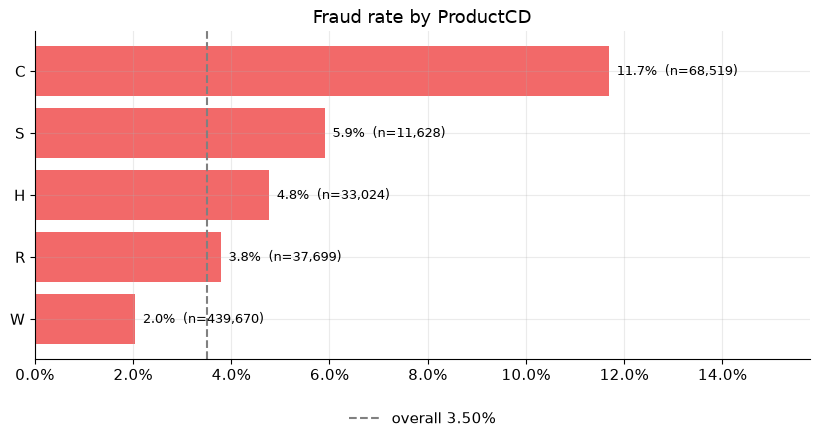

,count,fraud_rate
ProductCD,,
C,68519,0.1169
S,11628,0.0590
H,33024,0.0477
R,37699,0.0378
W,439670,0.0204


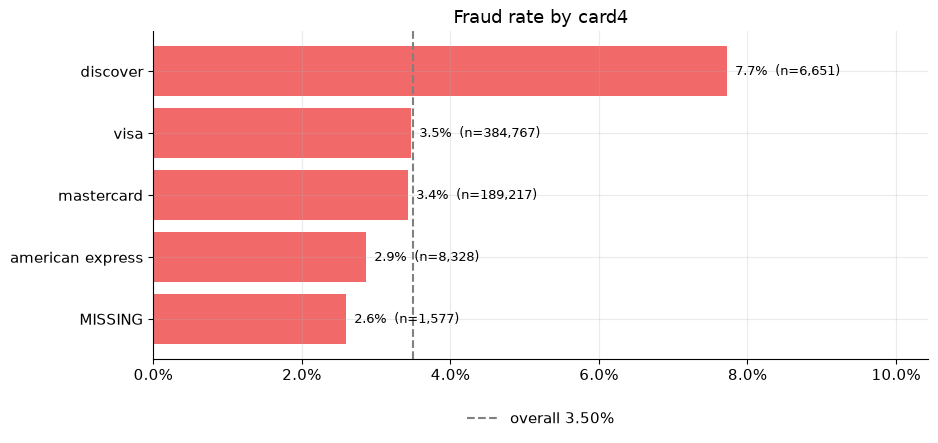

,count,fraud_rate
card4,,
discover,6651,0.0773
visa,384767,0.0348
mastercard,189217,0.0343
american express,8328,0.0287
MISSING,1577,0.0260


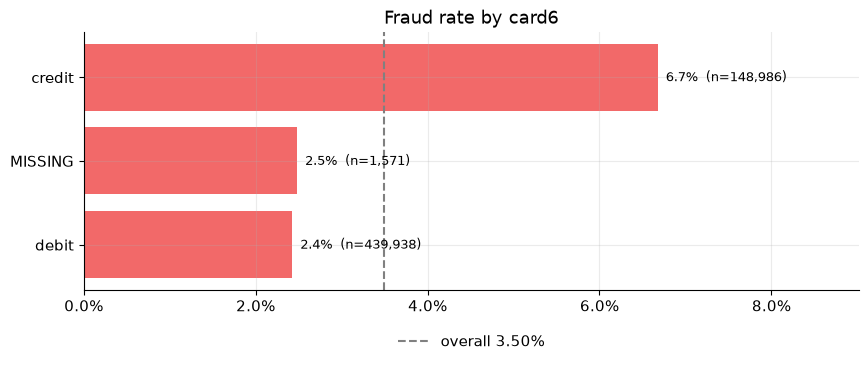

,count,fraud_rate
card6,,
credit,148986,0.0668
MISSING,1571,0.0248
debit,439938,0.0243


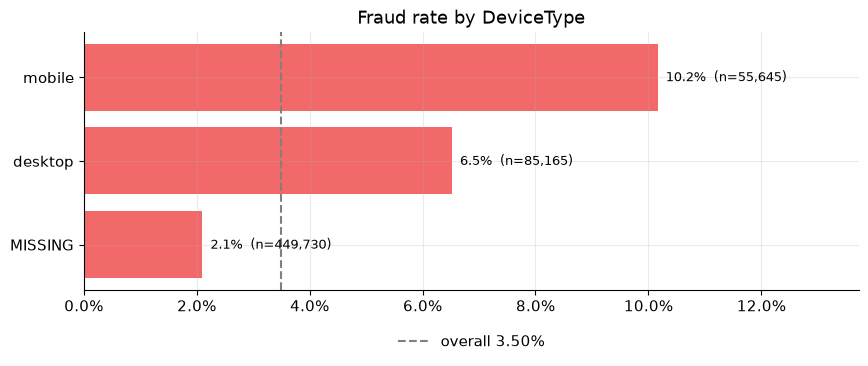

,count,fraud_rate
DeviceType,,
mobile,55645,0.1017
desktop,85165,0.0652
MISSING,449730,0.0210


In [13]:
def fraud_by(col, min_count=200, top_n=12, data=None):
    # Fraud rate per category value (NaN shown as 'MISSING'), for the most common values.
    data = df if data is None else data
    s = data[col].astype("object").fillna("MISSING").astype(str)
    t = data["isFraud"].groupby(s).agg(count="count", fraud_rate="mean")
    t = t[t["count"] >= min_count].sort_values("count", ascending=False).head(top_n)
    return t.sort_values("fraud_rate", ascending=False)


def plot_fraud_by(col, **kw):
    t = fraud_by(col, **kw)
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(t) + 2))
    labels = list(t.index)[::-1]
    rates = list(t["fraud_rate"])[::-1]
    counts = list(t["count"])[::-1]
    ax.barh(labels, rates, color=COLORS["fraud"], alpha=0.8)
    ax.axvline(fraud_rate, ls="--", color="gray", label=f"overall {fraud_rate:.2%}")
    for i, (r, c) in enumerate(zip(rates, counts)):
        ax.text(r, i, f"  {r:.1%}  (n={c:,})", va="center", fontsize=9)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlim(0, max(rates) * 1.35)
    ax.set_title(f"Fraud rate by {col}")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
    save_fig(f"05_fraud_rate_{col}")
    plt.show()
    return t


for col in ["ProductCD", "card4", "card6", "DeviceType"]:
    if col in df.columns:
        display(plot_fraud_by(col))

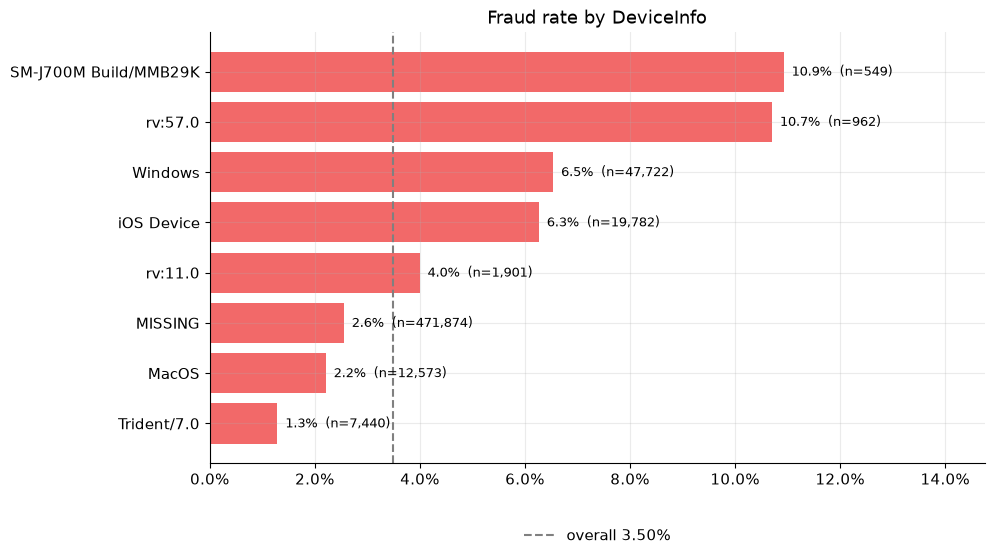

,count,fraud_rate
DeviceInfo,,
SM-J700M Build/MMB29K,549,0.1093
rv:57.0,962,0.1071
Windows,47722,0.0654
iOS Device,19782,0.0627
rv:11.0,1901,0.0400
MISSING,471874,0.0255
MacOS,12573,0.0221
Trident/7.0,7440,0.0129


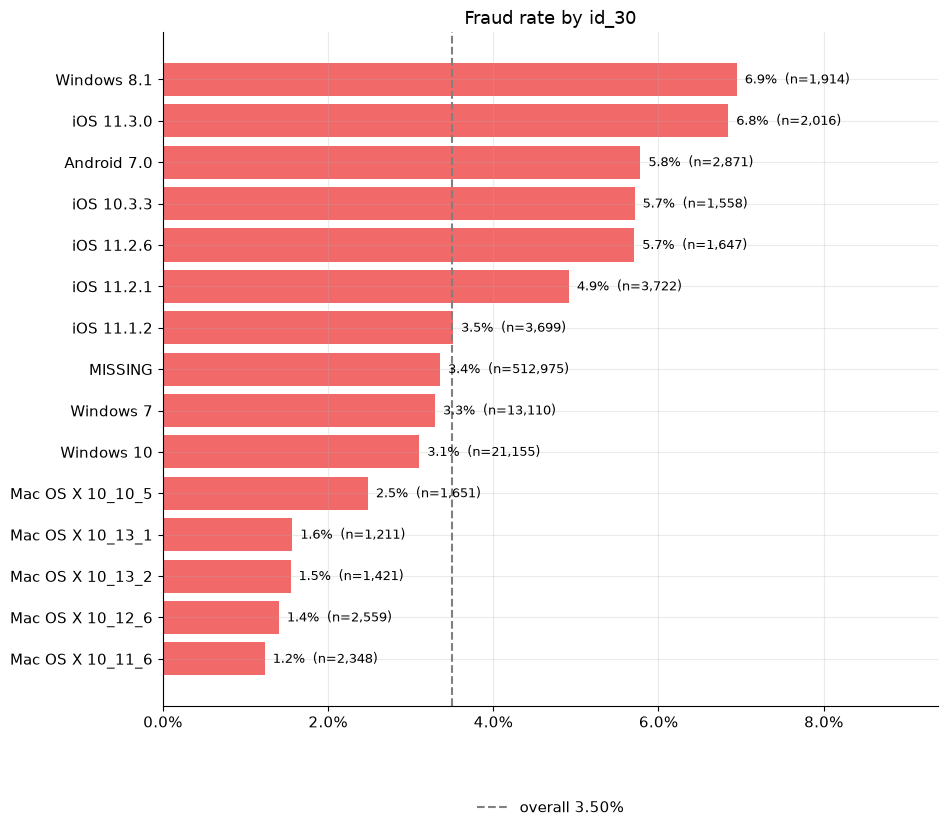

,count,fraud_rate
id_30,,
Windows 8.1,1914,0.0695
iOS 11.3.0,2016,0.0685
Android 7.0,2871,0.0578
iOS 10.3.3,1558,0.0571
iOS 11.2.6,1647,0.0571
iOS 11.2.1,3722,0.0492
iOS 11.1.2,3699,0.0351
MISSING,512975,0.0336
Windows 7,13110,0.0330


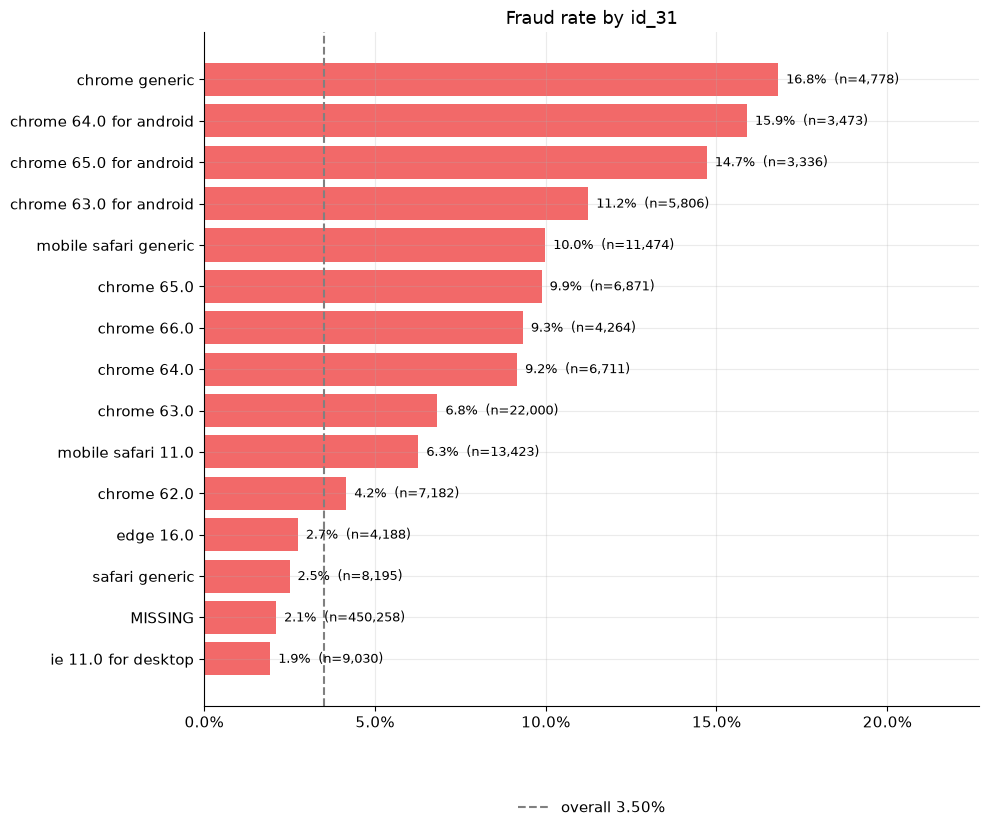

,count,fraud_rate
id_31,,
chrome generic,4778,0.1681
chrome 64.0 for android,3473,0.1589
chrome 65.0 for android,3336,0.1472
chrome 63.0 for android,5806,0.1125
mobile safari generic,11474,0.0999
chrome 65.0,6871,0.0988
chrome 66.0,4264,0.0933
chrome 64.0,6711,0.0916
chrome 63.0,22000,0.0683


In [14]:
# Device / browser / OS (identity table, high cardinality -> show only the most common values)
for col, min_n in [("DeviceInfo", 500), ("id_30", 500), ("id_31", 500)]:
    if col in df.columns:
        display(plot_fraud_by(col, min_count=min_n, top_n=15))

## 7. Email domains  *(tracker 1.7)*

`P_emaildomain` is the purchaser's email domain and `R_emaildomain` the recipient's. A purchaser / recipient *mismatch* can be a signal on its own.

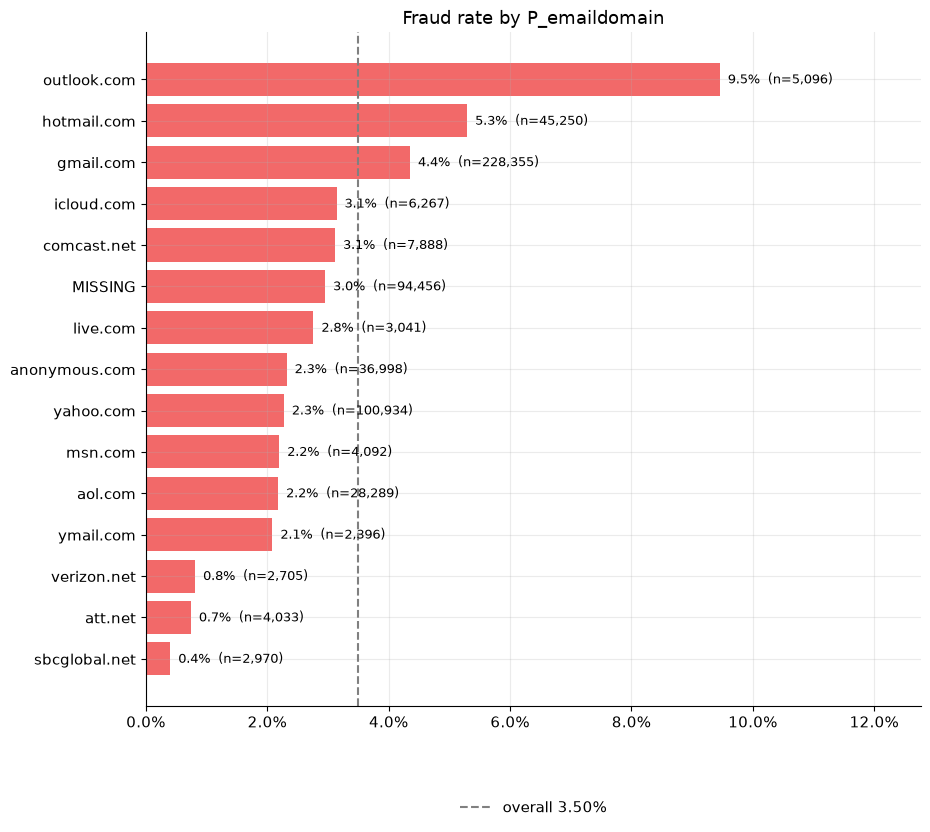

,count,fraud_rate
P_emaildomain,,
outlook.com,5096,0.0946
hotmail.com,45250,0.0530
gmail.com,228355,0.0435
icloud.com,6267,0.0314
comcast.net,7888,0.0312
MISSING,94456,0.0295
live.com,3041,0.0276
anonymous.com,36998,0.0232
yahoo.com,100934,0.0228


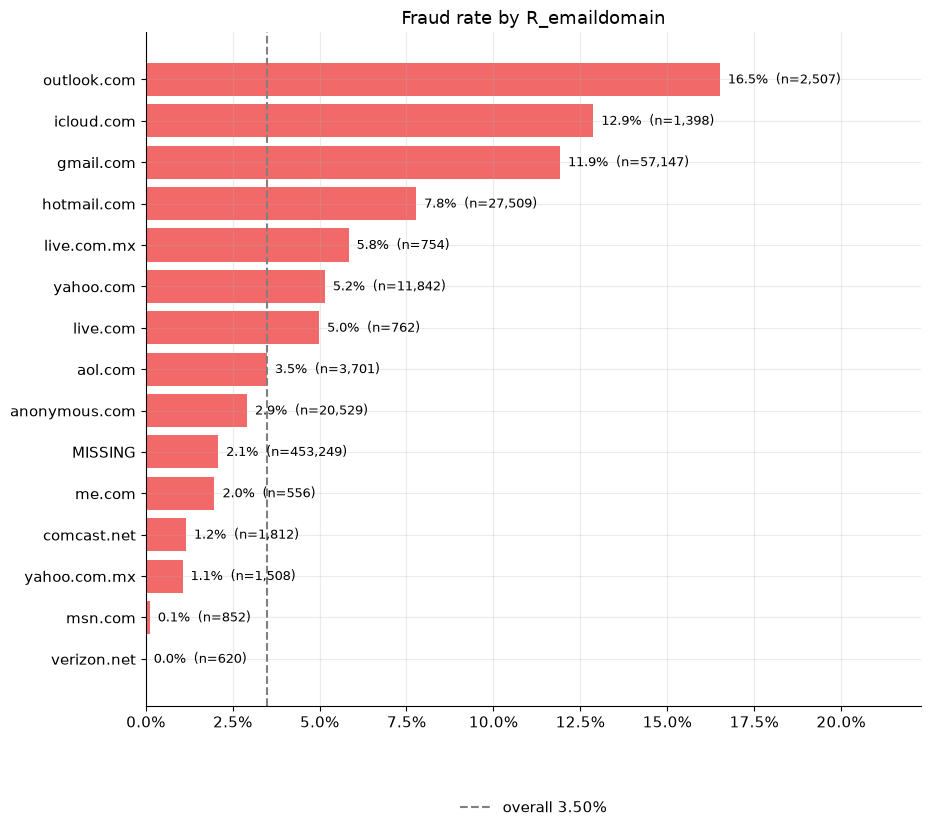

,count,fraud_rate
R_emaildomain,,
outlook.com,2507,0.1651
icloud.com,1398,0.1288
gmail.com,57147,0.1192
hotmail.com,27509,0.0778
live.com.mx,754,0.0584
yahoo.com,11842,0.0515
live.com,762,0.0499
aol.com,3701,0.0349
anonymous.com,20529,0.0291


C:\Users\aksha\AppData\Local\Temp\ipykernel_5908\2548199543.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["email_match"] = np.where(


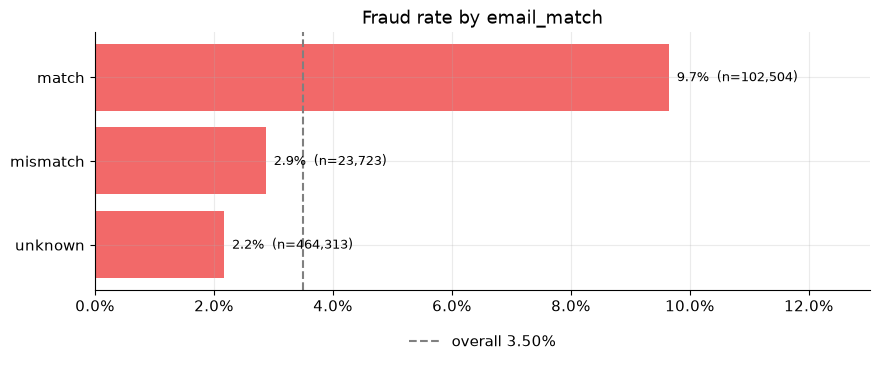

,count,fraud_rate
email_match,,
match,102504,0.0965
mismatch,23723,0.0287
unknown,464313,0.0217


In [15]:
for col in ["P_emaildomain", "R_emaildomain"]:
    display(plot_fraud_by(col, min_count=500, top_n=15))

# Purchaser vs recipient email match
p = df["P_emaildomain"].astype("object")
r = df["R_emaildomain"].astype("object")
df["email_match"] = np.where(
    p.isna() | r.isna(), "unknown",
    np.where(p.astype(str) == r.astype(str), "match", "mismatch"),
)
display(plot_fraud_by("email_match", min_count=1, top_n=5))
del p, r

## 8. Missingness patterns  *(tracker 1.8)*

In this dataset many columns are null for *structural* reasons (a field only exists for some transaction types or devices). That means **being null can carry signal**. Here we measure it instead of assuming.

In [16]:
null_pct_all = df.isna().mean() * 100


def col_group(c):
    if re.match(r"^V\d+$", c):   return "V (anonymized)"
    if re.match(r"^C\d+$", c):   return "C (counts)"
    if re.match(r"^D\d+$", c):   return "D (time deltas)"
    if re.match(r"^M\d+$", c):   return "M (match flags)"
    if c.startswith("id_"):      return "id (identity)"
    if c.startswith("card"):     return "card"
    if c.startswith("addr"):     return "addr"
    if c.startswith("dist"):     return "dist"
    if "email" in c:             return "email"
    return "other"


groups = pd.Series({c: col_group(c) for c in df.columns})
group_nulls = null_pct_all.groupby(groups).agg(n_cols="count", mean_null_pct="mean")
display(group_nulls.sort_values("mean_null_pct", ascending=False))

,n_cols,mean_null_pct
id (identity),38,84.8233
dist,2,76.6404
D (time deltas),15,58.1513
M (match flags),9,49.9233
V (anonymized),339,43.0385
email,3,30.9155
other,11,14.1874
addr,2,11.1264
card,6,0.5053
C (counts),14,0.0000


,null_pct,fraud_rate_if_null,fraud_rate_if_present,lift
column,,,,
D7,93.4099,0.0270,0.1488,0.1812
addr2,11.1264,0.1178,0.0246,4.7850
addr1,11.1264,0.1178,0.0246,4.7850
D12,89.0410,0.0248,0.1174,0.2116
D14,89.4695,0.0255,0.1160,0.2195
D13,89.5093,0.0262,0.1104,0.2370
D6,87.6068,0.0250,0.1055,0.2373
id_10,87.3123,0.0249,0.1045,0.2383
id_09,87.3123,0.0249,0.1045,0.2383


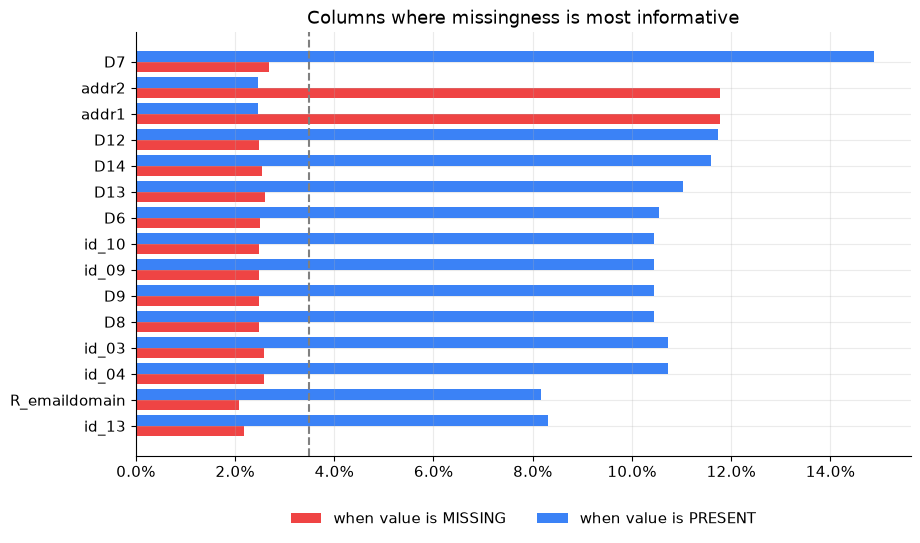

In [17]:
# For partially-null columns: is fraud more (or less) likely when the value is MISSING?
rows = []
for c in df.columns.drop("isFraud"):
    p = null_pct_all[c]
    if 1 <= p <= 99:
        m = df[c].isna()
        rows.append((c, p, y[m].mean(), y[~m].mean()))

miss = pd.DataFrame(rows, columns=["column", "null_pct", "fraud_rate_if_null", "fraud_rate_if_present"]).set_index("column")
miss["lift"] = (miss["fraud_rate_if_null"] / miss["fraud_rate_if_present"]).replace([np.inf, -np.inf], np.nan)
miss["abs_log_lift"] = np.abs(np.log(miss["lift"]))
top_miss = miss.sort_values("abs_log_lift", ascending=False).head(15).drop(columns="abs_log_lift")
display(top_miss)

fig, ax = plt.subplots(figsize=(10, 5.5))
t = top_miss.iloc[::-1]
ypos = np.arange(len(t))
ax.barh(ypos - 0.2, t["fraud_rate_if_null"], height=0.4, color=COLORS["fraud"], label="when value is MISSING")
ax.barh(ypos + 0.2, t["fraud_rate_if_present"], height=0.4, color=COLORS["legit"], label="when value is PRESENT")
ax.set_yticks(ypos)
ax.set_yticklabels(t.index)
ax.axvline(fraud_rate, ls="--", color="gray")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Columns where missingness is most informative")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
save_fig("06_missingness_signal")
plt.show()

**Takeaway to carry into Phase 2:** for the strongest columns above, keep (or add) an explicit `is_missing` indicator, and let tree models handle NaN natively instead of blindly filling with the mean.

## 9. Can we reconstruct a card identity?  *(tracker 1.9)*

There is **no card ID** in this dataset, but velocity features ("5 transactions on this card in 10 minutes") need one. The standard workaround is to combine card and address columns into a pseudo-ID.

We test two candidate definitions:

- **Key A:** `card1..card6` + `addr1` + `addr2`
- **Key B:** Key A + an **anchor day** = `day − D1`. `D1` behaves like "days since this card's first activity" (a community finding to verify here, not an official definition), so `day − D1` should be roughly constant for the same card and help separate different cards that share the same `card1..addr2` values.

**What a good key looks like:** few singleton groups, groups that are big enough to build history from, and fraud that *clusters* in a handful of groups (fraudsters hitting the same card repeatedly).

> ⚠️ Group sizes below are computed on the full dataset (EDA only). In Phase 2 every card-level feature must use **only earlier transactions**.

In [18]:
CARD_COLS = ["card1", "card2", "card3", "card4", "card5", "card6", "addr1", "addr2"]
df["d1_anchor"] = np.floor(df["day"] - df["D1"])  # NaN when D1 is missing


def group_stats(keys, label):
    gid = df.groupby(keys, dropna=False, observed=True).ngroup()
    size_per_group = gid.value_counts()
    fraud_per_group = y.groupby(gid).sum()
    txn_size = gid.map(size_per_group)                 # size of the group each transaction belongs to
    txn_group_fraud = gid.map(fraud_per_group)         # frauds in that transaction's group
    stats = {
        "definition": label,
        "n_groups": int(gid.nunique()),
        "singleton_groups_%": float((size_per_group == 1).mean() * 100),
        "median_group_size": float(size_per_group.median()),
        "txns_in_groups>=5_%": float((txn_size >= 5).mean() * 100),
        "groups_with_any_fraud": int((fraud_per_group > 0).sum()),
        "fraud_in_groups_with>=2_frauds_%": float(((txn_group_fraud >= 2) & (y == 1)).sum() / y.sum() * 100),
    }
    return stats, txn_size


stats_a, size_a = group_stats(CARD_COLS, "Key A: card1-6 + addr1-2")
stats_b, size_b = group_stats(CARD_COLS + ["d1_anchor"], "Key B: Key A + (day - D1)")

card_id_report = pd.DataFrame([stats_a, stats_b]).set_index("definition").T
display(card_id_report)

C:\Users\aksha\AppData\Local\Temp\ipykernel_5908\587070007.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["d1_anchor"] = np.floor(df["day"] - df["D1"])  # NaN when D1 is missing


definition,Key A: card1-6 + addr1-2,Key B: Key A + (day - D1)
n_groups,"43,071.0000","222,518.0000"
singleton_groups_%,40.4147,57.9764
median_group_size,2.0000,1.0000
txns_in_groups>=5_%,91.6312,50.0290
groups_with_any_fraud,"3,548.0000","8,199.0000"
fraud_in_groups_with>=2_frauds_%,91.6711,77.7041


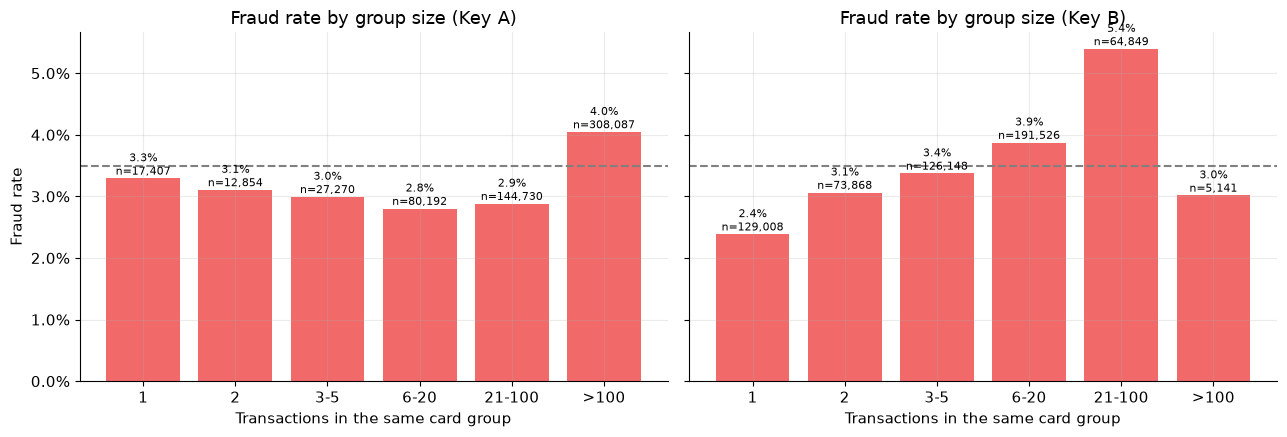

In [19]:
# Does fraud rate depend on how big the card group is? (Useful for deciding how much history a card needs.)
buckets = [0, 1, 2, 5, 20, 100, np.inf]
labels = ["1", "2", "3-5", "6-20", "21-100", ">100"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, size, title in [(axes[0], size_a, "Key A"), (axes[1], size_b, "Key B")]:
    b = pd.cut(size, bins=buckets, labels=labels)
    t = df["isFraud"].groupby(b, observed=True).agg(count="count", fraud_rate="mean")
    ax.bar(t.index.astype(str), t["fraud_rate"], color=COLORS["fraud"], alpha=0.8)
    for i, (r, c) in enumerate(zip(t["fraud_rate"], t["count"])):
        ax.text(i, r, f"{r:.1%}\nn={c:,}", ha="center", va="bottom", fontsize=8)
    ax.axhline(fraud_rate, ls="--", color="gray")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("Transactions in the same card group")
    ax.set_title(f"Fraud rate by group size ({title})")
axes[0].set_ylabel("Fraud rate")
plt.tight_layout()
save_fig("07_card_group_size_fraud")
plt.show()

**How to choose:** prefer the key with fewer singleton groups *and* higher fraud concentration, but also sanity-check it by eye on a few large groups in Phase 2 (amounts, devices, and timing should look like one cardholder). An imperfect key is acceptable as long as it is documented, because it is a heuristic, not ground truth.

## 10. Extra signals: C and D columns

`C1–C14` are anonymized count-style features and `D1–D15` are time-delta-style features. Their meaning is hidden, but a quick correlation scan shows which ones are worth engineering around in Phase 2.

,corr_with_isFraud
D8,-0.1426
D7,-0.1272
D2,-0.0836
D15,-0.0775
D10,-0.0720
D4,-0.0672
D1,-0.0672
D5,-0.0646
D13,-0.0594
D6,-0.0572


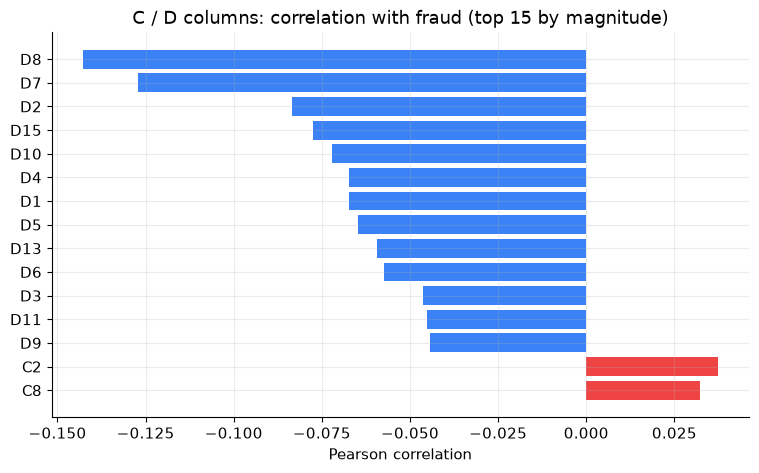

Correlation only catches linear relationships. Tree models may find more; confirm with SHAP in Phase 4.


In [20]:
num_cols = [c for c in df.columns if re.match(r"^(C|D)\d+$", c)]
corr = df[num_cols].corrwith(y.astype("float32")).dropna()
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15)
display(top_corr.to_frame("corr_with_isFraud"))

fig, ax = plt.subplots(figsize=(9, 5))
t = top_corr.iloc[::-1]
ax.barh(t.index, t.values, color=[COLORS["fraud"] if v > 0 else COLORS["legit"] for v in t.values])
ax.set_title("C / D columns: correlation with fraud (top 15 by magnitude)")
ax.set_xlabel("Pearson correlation")
save_fig("08_cd_correlation")
plt.show()
print("Correlation only catches linear relationships. Tree models may find more; confirm with SHAP in Phase 4.")

## 11. Key findings  *(tracker 1.10)*

> ✍️ **Fill this in yourself after running the notebook.** Write in business language, not statistics jargon, and always include a number. The prompts below tell you where to look; delete the prompts when done.

1. **Imbalance:** *(Section 3)* Fraud is ___% of transactions, so ___. Accuracy is meaningless; we will use PR-AUC and recall at a fixed false-positive rate.
2. **Time:** *(Section 4)* Fraud rate across days is ___ (stable / drifting / spiky). We split by time at day ___ and day ___, giving train / validation / holdout fraud rates of ___ / ___ / ___.
3. **Amount:** *(Section 5)* Fraudulent amounts are ___ than legitimate ones (median ___ vs ___). The riskiest amount bands are ___.
4. **Who is riskier:** *(Sections 6–7)* The riskiest segments are ___ (fraud rate ___ vs ___ overall). Email domain / mismatch ___.
5. **Missingness:** *(Section 8)* Missing ___ is associated with a ___× change in fraud rate, so we will keep explicit missing indicators.
6. **Card identity:** *(Section 9)* We will use Key ___ because ___ (singleton ___%, fraud concentration ___%).
7. **Identity coverage:** *(Section 2)* Only ___% of transactions have identity data and their fraud rate is ___ vs ___, so the API must handle "no identity" inputs.

### Handoff to Phase 2 (feature engineering)
- [ ] Use the time-based split saved in `ml/artifacts/eda_summary.json`
- [ ] Build card-level features from the chosen card key using **past transactions only**
- [ ] Add missing indicators for the top informative columns
- [ ] Treat `hour_rel` / `dow_rel` as relative features, not real clock times
- [ ] Keep the readable fields (amount, product, card network/type, address, email domain, device) available for the demo form and the explanations

## 12. Save EDA summary for the next phase

In [21]:
summary = {
    "n_transactions": int(len(df)),
    "n_columns_merged": int(df.shape[1]),
    "fraud_rate": float(fraud_rate),
    "has_identity_pct": float(df["has_identity"].mean() * 100),
    "proposed_split": {
        "train_end_dt": train_end_dt,
        "val_end_dt": val_end_dt,
        "max_dt": max_dt,
        "train_end_day": int(train_end_dt // 86400),
        "val_end_day": int(val_end_dt // 86400),
        "note": "train: DT <= train_end_dt | validation: train_end_dt < DT <= val_end_dt | holdout: DT > val_end_dt",
    },
    "card_identity_candidates": [stats_a, stats_b],
    "top_missingness_signals": top_miss.round(4).reset_index().to_dict(orient="records"),
}

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
out_path = ARTIFACTS_DIR / "eda_summary.json"
with open(out_path, "w") as f:
    json.dump(summary, f, indent=2, default=float)
print("Saved:", out_path.resolve())

Saved: C:\VS CODE\PROJECTS\FraudShield AI\ml\artifacts\eda_summary.json


---
**Next:** Phase 2 — `02_Feature_Engineering.ipynb`. Build the shared, leakage-safe feature module in `backend/app/features/`, using the time split, card key, and missingness findings from this notebook.